In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder

from sklearn.feature_selection import (
    SelectKBest,
    chi2,
    mutual_info_classif
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    recall_score,
    precision_score,
    f1_score
)



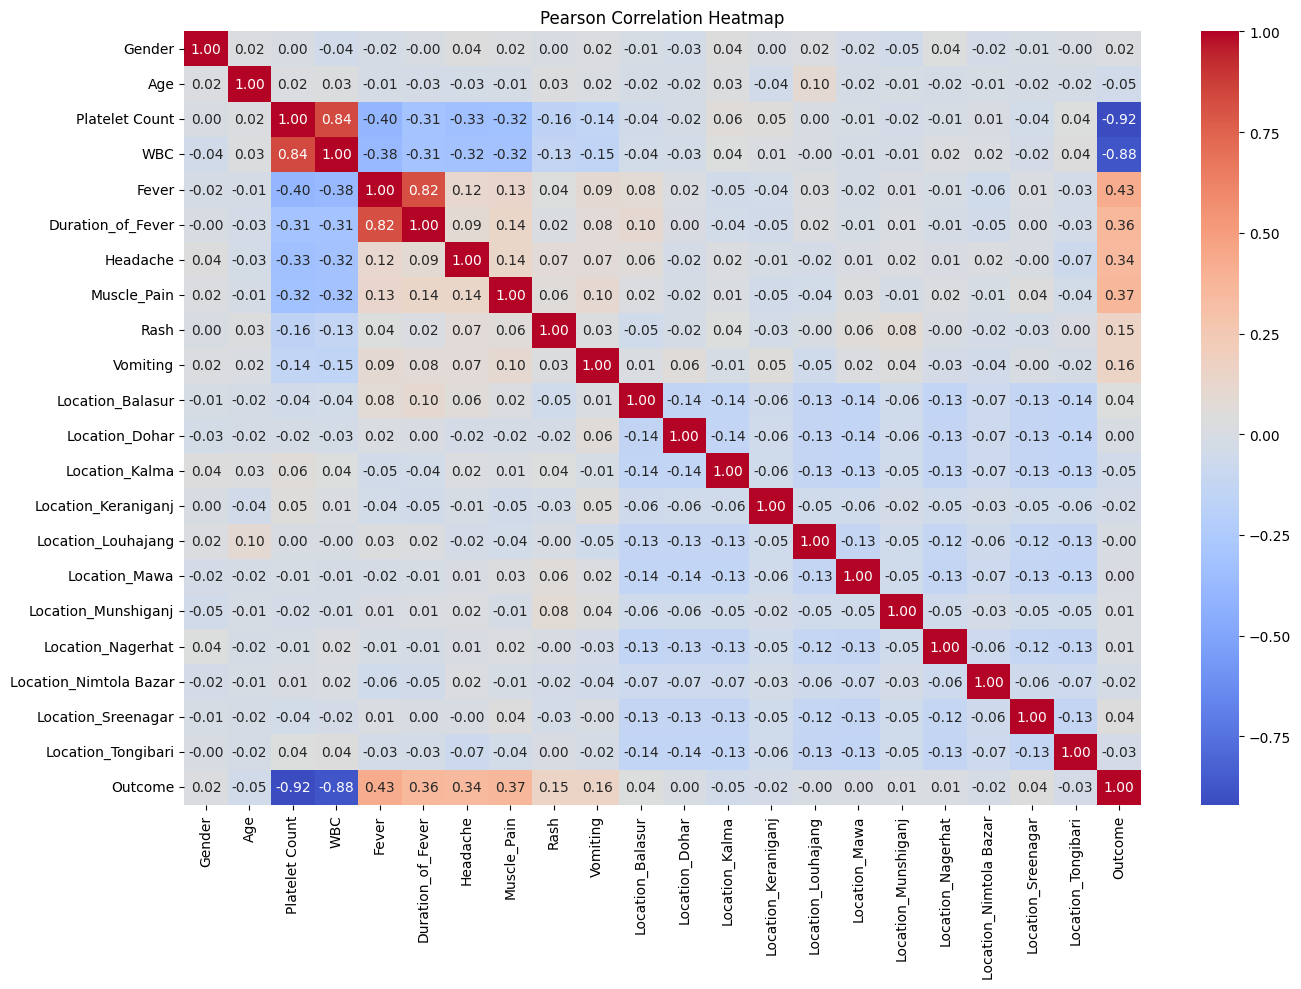

In [ ]:
#=========================================================
# LOAD DATASET
# =========================================================

df = pd.read_csv(r"C:/Users/AWOPETU/Desktop/IMPLEMENTATION/TRAINING/Dengue_clinical_dataset.csv")


# =========================================================
# FEATURES AND TARGET
# =========================================================
if df.isnull().values.any():       # checking for empty/null values
    df = pd.get_dummies(
        df,
        columns=['Location'],       #one hot encoding 'location'
    )
    df = df.drop(columns=['ID'])      #removing "id" column
    
    le = LabelEncoder()                             #label encoding binary features
    columns_to_convert = ['Gender', 'Fever', 'Headache', 'Muscle_Pain', 'Rash', 'Vomiting', 'Outcome']

    for col in columns_to_convert:
        df[col] = le.fit_transform(df[col])

    cols = [col for col in df.columns if col != 'Outcome'] + ['Outcome']

    df = df[cols]                               

correlation_matrix = df.corr(method='pearson')
plt.figure(figsize=(14,10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Pearson Correlation Heatmap")

plt.tight_layout()

plt.show()

# Replace 'Outcome' with your actual target column name
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# =========================================================
# NUMBER OF FEATURES TO SELECT
# =========================================================

k = 8

# =========================================================
# FEATURE SELECTION TECHNIQUES
# =========================================================

feature_selection_results = {}


In [4]:
scaler1 = MinMaxScaler()
scaler2 = StandardScaler()
X_scaled1 = scaler1.fit_transform(X)
X_scaled2 = scaler2.fit_transform(X)
chi_scores, _ = chi2(X_scaled1, y)

# Pearson
pearson_scores = X.apply(lambda col: abs(col.corr(y)))

# Mutual Information
mi_scores = mutual_info_classif(X_scaled2, y, random_state=42)

# Combine into a table
scores_df = pd.DataFrame({
    'Feature': X.columns,
    'Chi-Square Score': chi_scores.round(4),
    'Pearson Score': pearson_scores.round(4),
    'Mutual Information Score': mi_scores.round(4)
}).sort_values('Mutual Information Score', ascending=False)

print(scores_df.to_string(index=False))

               Feature  Chi-Square Score  Pearson Score  Mutual Information Score
        Platelet Count          142.0843         0.9196                    0.5626
                   WBC          178.9674         0.8763                    0.5605
                 Fever           29.9312         0.4272                    0.0897
     Duration_of_Fever           22.2564         0.3560                    0.0773
              Headache           28.7659         0.3441                    0.0694
           Muscle_Pain           50.8325         0.3687                    0.0520
        Location_Dohar            0.0004         0.0006                    0.0435
              Vomiting           17.5088         0.1596                    0.0287
         Location_Mawa            0.0107         0.0034                    0.0181
   Location_Keraniganj            0.6150         0.0249                    0.0140
     Location_Nagerhat            0.1540         0.0131                    0.0098
                

In [ ]:

# ---------------------------------------------------------
# 1. CHI-SQUARE FEATURE SELECTION
# ---------------------------------------------------------

# Chi2 requires non-negative values
chi2_scaler = MinMaxScaler()

X_chi2_scaled = chi2_scaler.fit_transform(X)

chi2_selector = SelectKBest(score_func=chi2, k=k)

X_chi2 = chi2_selector.fit_transform(X_chi2_scaled, y)

# Get selected feature names
chi2_selected_features = X.columns[chi2_selector.get_support()]

# Get scores
chi2_scores = chi2_selector.scores_[chi2_selector.get_support()]

# Create dataframe
chi2_feature_scores = pd.DataFrame({
    'Feature': chi2_selected_features,
    'Score': chi2_scores
})

# Sort descending
chi2_feature_scores = chi2_feature_scores.sort_values(
    by='Score',
    ascending=False
)

feature_selection_results["Chi2"] = {
    "X": X_chi2,
    "features": chi2_selected_features
}

print("\n==============================")
print("CHI2 SELECTED FEATURES")
print("==============================")

print(chi2_feature_scores)


CHI2 SELECTED FEATURES
             Feature       Score
1                WBC  178.967407
0     Platelet Count  142.084256
5        Muscle_Pain   50.832467
2              Fever   29.931164
4           Headache   28.765863
3  Duration_of_Fever   22.256427
7           Vomiting   17.508797
6               Rash   12.916165


In [ ]:
# ---------------------------------------------------------
# 2. PEARSON CORRELATION FEATURE SELECTION
# ---------------------------------------------------------

# Combine features and target temporarily
pearson_df = X.copy()
pearson_df["Diagnosis"] = y

# Compute correlations
correlations = pearson_df.corr()["Diagnosis"].drop("Diagnosis")

# Absolute correlation values
correlations = correlations.abs()

# Sort descending
correlations = correlations.sort_values(ascending=False)

# Select top k features
pearson_selected_features = correlations.head(k).index

X_pearson = X[pearson_selected_features]

# Create dataframe
pearson_feature_scores = pd.DataFrame({
    'Feature': correlations.head(k).index,
    'Score': correlations.head(k).values
})

feature_selection_results["Pearson"] = {
    "X": X_pearson,
    "features": pearson_selected_features
}

print("\n==============================")
print("PEARSON SELECTED FEATURES")
print("==============================")

print(pearson_feature_scores)


PEARSON SELECTED FEATURES
             Feature     Score
0     Platelet Count  0.919649
1                WBC  0.876316
2              Fever  0.427208
3        Muscle_Pain  0.368667
4  Duration_of_Fever  0.355998
5           Headache  0.344061
6           Vomiting  0.159643
7               Rash  0.153524


In [ ]:
# ---------------------------------------------------------
# 3. MUTUAL INFORMATION FEATURE SELECTION
# ---------------------------------------------------------


from sklearn.feature_selection import mutual_info_classif

# Compute Mutual Information scores
mi_scores = mutual_info_classif(X, y, random_state=42)

# Create DataFrame of ALL feature scores
mi_feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'MI Score': mi_scores
})

# Sort scores from highest to lowest
mi_feature_scores = mi_feature_scores.sort_values(
    by='MI Score',
    ascending=False
)

# Print ALL feature scores
print("\n===================================")
print("MUTUAL INFORMATION FEATURE SCORES")
print("===================================\n")



top_k = 8  

selected_mi_features = mi_feature_scores.head(top_k)

print("\n===================================")
print(f"TOP {top_k} FEATURES SELECTED")
print("===================================\n")

print(selected_mi_features.to_string(index=False))

# Feature names only
mi_selected_feature_names = selected_mi_features['Feature'].tolist()

# Selected dataset
X_mi = X[mi_selected_feature_names]
print(X_mi.columns)

feature_selection_results["Mutual info"] = {
    "X": X_mi,
    "features": mi_selected_feature_names
    
}


MUTUAL INFORMATION FEATURE SCORES


TOP 8 FEATURES SELECTED

          Feature  MI Score
   Platelet Count  0.562602
              WBC  0.560531
            Fever  0.090067
Duration_of_Fever  0.077281
         Headache  0.069398
      Muscle_Pain  0.052029
   Location_Dohar  0.043153
         Vomiting  0.029101
Index(['Platelet Count', 'WBC', 'Fever', 'Duration_of_Fever', 'Headache',
       'Muscle_Pain', 'Location_Dohar', 'Vomiting'],
      dtype='str')


In [ ]:
# =========================================================
# MODELS
# =========================================================

models = {
    "Random Forest": RandomForestClassifier(
        random_state=99
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "SVM": SVC()
}


In [ ]:

# =========================================================
# STORE RESULTS
# =========================================================

results = []





FEATURE SELECTION: Chi2
MODEL: Random Forest

Accuracy: 0.9951

Recall: 0.9929

Precision: 1.0000

F1 score: 0.9964

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        64
           1       1.00      0.99      1.00       140

    accuracy                           1.00       204
   macro avg       0.99      1.00      0.99       204
weighted avg       1.00      1.00      1.00       204


Confusion Matrix:
[[ 64   0]
 [  1 139]]


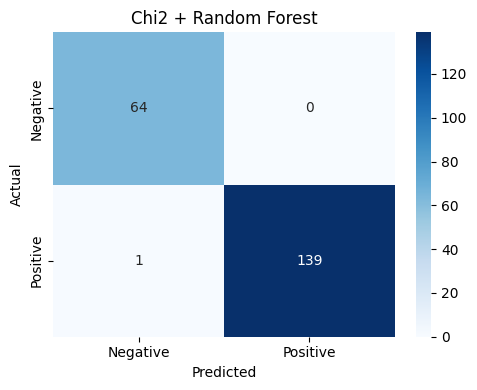



FEATURE SELECTION: Chi2
MODEL: Logistic Regression

Accuracy: 0.9902

Recall: 0.9929

Precision: 0.9929

F1 score: 0.9929

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        64
           1       0.99      0.99      0.99       140

    accuracy                           0.99       204
   macro avg       0.99      0.99      0.99       204
weighted avg       0.99      0.99      0.99       204


Confusion Matrix:
[[ 63   1]
 [  1 139]]


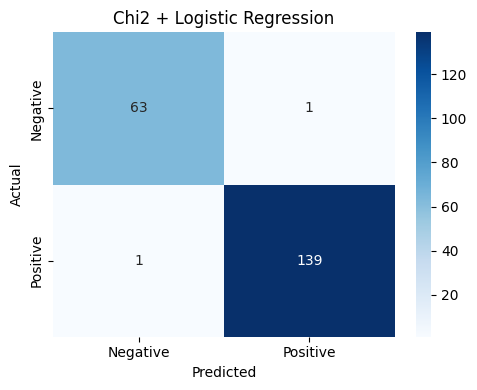



FEATURE SELECTION: Chi2
MODEL: SVM

Accuracy: 0.9902

Recall: 0.9929

Precision: 0.9929

F1 score: 0.9929

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        64
           1       0.99      0.99      0.99       140

    accuracy                           0.99       204
   macro avg       0.99      0.99      0.99       204
weighted avg       0.99      0.99      0.99       204


Confusion Matrix:
[[ 63   1]
 [  1 139]]


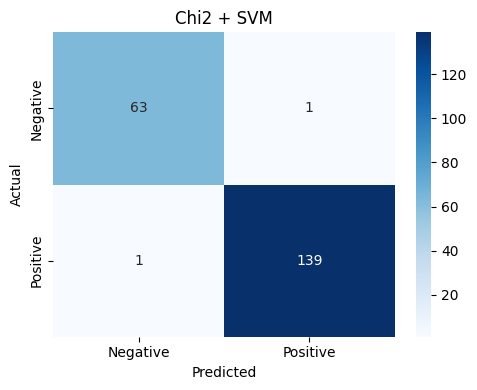



FEATURE SELECTION: Pearson
MODEL: Random Forest

Accuracy: 0.9902

Recall: 0.9929

Precision: 0.9929

F1 score: 0.9929

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        64
           1       0.99      0.99      0.99       140

    accuracy                           0.99       204
   macro avg       0.99      0.99      0.99       204
weighted avg       0.99      0.99      0.99       204


Confusion Matrix:
[[ 63   1]
 [  1 139]]


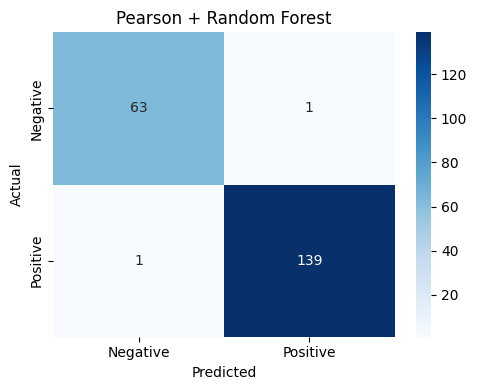



FEATURE SELECTION: Pearson
MODEL: Logistic Regression

Accuracy: 0.9902

Recall: 0.9929

Precision: 0.9929

F1 score: 0.9929

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        64
           1       0.99      0.99      0.99       140

    accuracy                           0.99       204
   macro avg       0.99      0.99      0.99       204
weighted avg       0.99      0.99      0.99       204


Confusion Matrix:
[[ 63   1]
 [  1 139]]


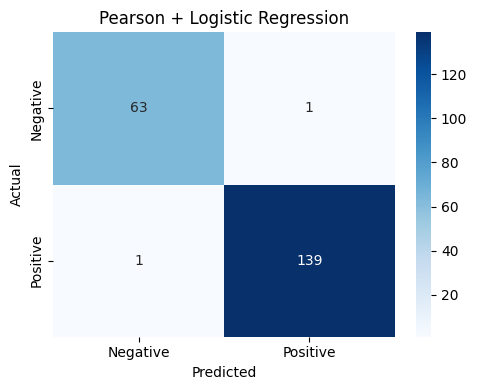



FEATURE SELECTION: Pearson
MODEL: SVM

Accuracy: 0.9902

Recall: 0.9929

Precision: 0.9929

F1 score: 0.9929

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        64
           1       0.99      0.99      0.99       140

    accuracy                           0.99       204
   macro avg       0.99      0.99      0.99       204
weighted avg       0.99      0.99      0.99       204


Confusion Matrix:
[[ 63   1]
 [  1 139]]


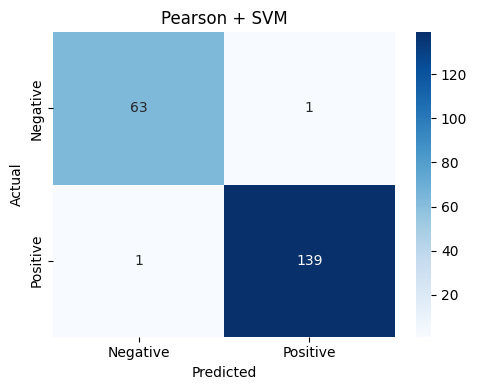



FEATURE SELECTION: Mutual info
MODEL: Random Forest

Accuracy: 0.9951

Recall: 0.9929

Precision: 1.0000

F1 score: 0.9964

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        64
           1       1.00      0.99      1.00       140

    accuracy                           1.00       204
   macro avg       0.99      1.00      0.99       204
weighted avg       1.00      1.00      1.00       204


Confusion Matrix:
[[ 64   0]
 [  1 139]]


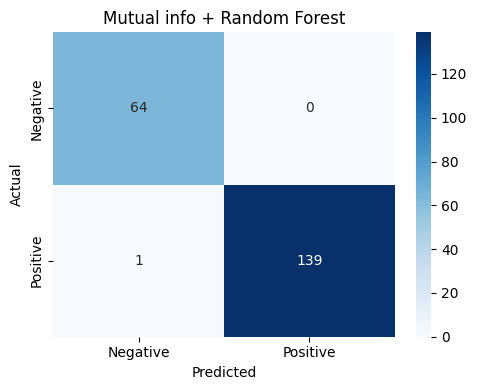



FEATURE SELECTION: Mutual info
MODEL: Logistic Regression

Accuracy: 0.9902

Recall: 0.9929

Precision: 0.9929

F1 score: 0.9929

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        64
           1       0.99      0.99      0.99       140

    accuracy                           0.99       204
   macro avg       0.99      0.99      0.99       204
weighted avg       0.99      0.99      0.99       204


Confusion Matrix:
[[ 63   1]
 [  1 139]]


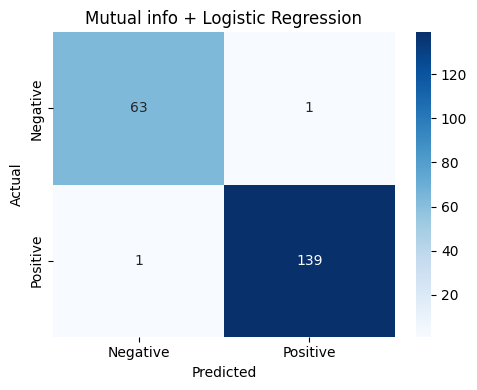



FEATURE SELECTION: Mutual info
MODEL: SVM

Accuracy: 0.9902

Recall: 0.9929

Precision: 0.9929

F1 score: 0.9929

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        64
           1       0.99      0.99      0.99       140

    accuracy                           0.99       204
   macro avg       0.99      0.99      0.99       204
weighted avg       0.99      0.99      0.99       204


Confusion Matrix:
[[ 63   1]
 [  1 139]]


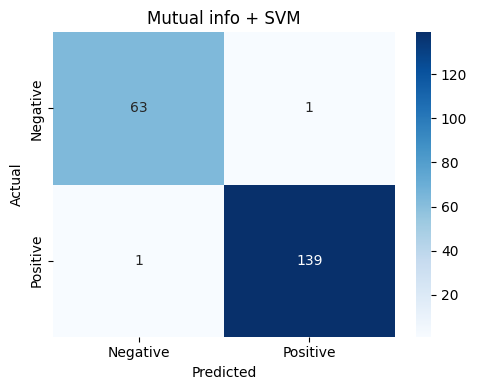

In [ ]:
# =========================================================
# TRAINING + EVALUATION
# =========================================================

for fs_name, fs_data in feature_selection_results.items():

    X_selected = fs_data["X"]

    # -----------------------------------------------------
    # TRAIN TEST SPLIT AFTER FEATURE SELECTION
    # -----------------------------------------------------

    X_train, X_test, y_train, y_test = train_test_split(
        X_selected,
        y,
        test_size=0.2,
        random_state=99,
        stratify=y
    )

    for model_name, model in models.items():

        print("\n")
        print("================================================")
        print(f"FEATURE SELECTION: {fs_name}")
        print(f"MODEL: {model_name}")
        print("================================================")

        # -------------------------------------------------
        # STANDARD SCALING FOR LR AND SVM
        # -------------------------------------------------

        if model_name in ["Logistic Regression", "SVM"]:

            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_test_scaled)

        else:
            # Random Forest does not need scaling

            model.fit(X_train, y_train)

            y_pred = model.predict(X_test)

        # -------------------------------------------------
        # EVALUATION
        # -------------------------------------------------

        accuracy = accuracy_score(y_test, y_pred)
        recall = recall_score(y_test,y_pred)
        precision = precision_score(y_test,y_pred)
        f1score = f1_score(y_test,y_pred)

        print(f"\nAccuracy: {accuracy:.4f}")
        print(f"\nRecall: {recall:.4f}")
        print(f"\nPrecision: {precision:.4f}")
        print(f"\nF1 score: {f1score:.4f}")

        print("\nClassification Report:")
        print(classification_report(y_test, y_pred))

        # -------------------------------------------------
        # CONFUSION MATRIX
        # -------------------------------------------------

        cm = confusion_matrix(y_test, y_pred)

        print("\nConfusion Matrix:")
        print(cm)

        # -------------------------------------------------
        # CONFUSION MATRIX VISUALIZATION
        # -------------------------------------------------

        plt.figure(figsize=(5, 4))

        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"]
        )

        plt.title(f"{fs_name} + {model_name}")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")

        plt.tight_layout()

        plt.show()

        # -------------------------------------------------
        # SAVE RESULTS
        # -------------------------------------------------

        results.append({
            "Feature Selection": fs_name,
            "Model": model_name,
            "Accuracy": accuracy
        })



In [ ]:
# =========================================================
# RESULTS TABLE
# =========================================================

results_df = pd.DataFrame(results)

print("\n")
print("===================================")
print("FINAL RESULTS")
print("===================================")

print(results_df)





FINAL RESULTS
  Feature Selection                Model  Accuracy
0              Chi2        Random Forest  0.995098
1              Chi2  Logistic Regression  0.990196
2              Chi2                  SVM  0.990196
3           Pearson        Random Forest  0.990196
4           Pearson  Logistic Regression  0.990196
5           Pearson                  SVM  0.990196
6       Mutual info        Random Forest  0.995098
7       Mutual info  Logistic Regression  0.990196
8       Mutual info                  SVM  0.990196
